# 5.1.1 — Load the spatial grid

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
grid_file = "data/chicago_spatial_grid.csv"

grid_nodes = pd.read_csv(grid_file)

print("Grid loaded successfully.")
print("Number of nodes:", len(grid_nodes))
print("Columns:", list(grid_nodes.columns))

display(grid_nodes.head())

Grid loaded successfully.
Number of nodes: 157
Columns: ['GRID_ID', 'GRID_ROW', 'GRID_COL', 'GRID_CENTER_LAT', 'GRID_CENTER_LON', 'CRIME_COUNT']


,GRID_ID,GRID_ROW,GRID_COL,GRID_CENTER_LAT,GRID_CENTER_LON,CRIME_COUNT
0,0_9,0,9,41.654160,-87.644006,218
1,0_10,0,10,41.654305,-87.617586,595
2,0_11,0,11,41.654444,-87.591166,559
3,0_12,0,12,41.654577,-87.564745,121
4,0_13,0,13,41.654704,-87.538324,451


# 5.1.2 — Create node IDs

In [3]:
grid_nodes = grid_nodes.reset_index(drop=True)

grid_nodes["NODE_ID"] = grid_nodes.index

print("Node IDs assigned.")

display(
    grid_nodes[
        [
            "NODE_ID",
            "GRID_ID",
            "GRID_CENTER_LAT",
            "GRID_CENTER_LON",
            "CRIME_COUNT"
        ]
    ].head(10)
)

Node IDs assigned.


,NODE_ID,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,CRIME_COUNT
0,0,0_9,41.654160,-87.644006,218
1,1,0_10,41.654305,-87.617586,595
2,2,0_11,41.654444,-87.591166,559
3,3,0_12,41.654577,-87.564745,121
4,4,0_13,41.654704,-87.538324,451
5,5,1_6,41.673503,-87.723487,2
6,6,1_7,41.673666,-87.697060,25
7,7,1_8,41.673823,-87.670632,441
8,8,1_9,41.673975,-87.644204,1332
9,9,1_10,41.674120,-87.617775,1181


# 5.1.3 — Set the neighborhood distance

In [4]:
NEIGHBOR_RADIUS_KM = 3.0
NEIGHBOR_RADIUS_M = NEIGHBOR_RADIUS_KM * 1000

print(
    f"Neighborhood radius: "
    f"{NEIGHBOR_RADIUS_KM} km"
)

Neighborhood radius: 3.0 km


# 5.1.4 — Understand why we need KD-tree

### We have only 157 nodes, so technically we could calculate every pair of distances. But the research paper specifically uses a KD-tree for efficient spatial neighbor search.

In [6]:
# !pip install scipy

from scipy.spatial import cKDTree

print("cKDTree imported successfully.")

cKDTree imported successfully.


# 5.1.5 — Build the KD-tree

In [7]:
from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:26916",
    always_xy=True
)

grid_x, grid_y = transformer.transform(
    grid_nodes["GRID_CENTER_LON"].values,
    grid_nodes["GRID_CENTER_LAT"].values
)

grid_nodes["X_M"] = grid_x
grid_nodes["Y_M"] = grid_y

print("Grid centroids converted to meters.")

display(
    grid_nodes[
        [
            "NODE_ID",
            "GRID_CENTER_LAT",
            "GRID_CENTER_LON",
            "X_M",
            "Y_M"
        ]
    ].head()
)

Grid centroids converted to meters.


,NODE_ID,GRID_CENTER_LAT,GRID_CENTER_LON,X_M,Y_M
0,0,41.654160,-87.644006,446376.990389,4.611579e+06
1,1,41.654305,-87.617586,448576.990389,4.611579e+06
2,2,41.654444,-87.591166,450776.990389,4.611579e+06
3,3,41.654577,-87.564745,452976.990389,4.611579e+06
4,4,41.654704,-87.538324,455176.990389,4.611579e+06


# 5.1.6 — Build KD-tree

In [8]:
coordinates_m = grid_nodes[
    ["X_M", "Y_M"]
].values

tree = cKDTree(coordinates_m)

print("KD-tree created successfully.")

KD-tree created successfully.


# 5.1.7 — Find neighbors within 3 km

In [9]:
neighbor_lists = tree.query_ball_point(
    coordinates_m,
    r=NEIGHBOR_RADIUS_M
)

print("Neighbor search completed.")

for i in range(5):
    print(
        f"Node {i}: "
        f"{len(neighbor_lists[i])} nodes within 3 km"
    )

Neighbor search completed.
Node 0: 3 nodes within 3 km
Node 1: 4 nodes within 3 km
Node 2: 4 nodes within 3 km
Node 3: 4 nodes within 3 km
Node 4: 3 nodes within 3 km


# 5.1.8 — Create the edge list

In [10]:
edges = []

for source_node, neighbors in enumerate(neighbor_lists):

    for target_node in neighbors:

        # Remove self-loop
        if source_node == target_node:
            continue

        edges.append(
            (source_node, target_node)
        )

print("Directed edges before removing duplicates:", len(edges))

Directed edges before removing duplicates: 544


# 5.1.9 — Create an undirected edge list

In [11]:
undirected_edges = set()

for source, target in edges:

    edge = tuple(sorted((source, target)))

    undirected_edges.add(edge)

print(
    "Number of unique undirected edges:",
    len(undirected_edges)
)

Number of unique undirected edges: 272


# 5.1.10 — Calculate graph degree

In [12]:
degree = np.zeros(
    len(grid_nodes),
    dtype=int
)

for source, target in undirected_edges:

    degree[source] += 1
    degree[target] += 1

grid_nodes["DEGREE"] = degree

print("Graph degree statistics:")
print(grid_nodes["DEGREE"].describe())

Graph degree statistics:
count    157.000000
mean       3.464968
std        0.812788
min        1.000000
25%        3.000000
50%        4.000000
75%        4.000000
max        4.000000
Name: DEGREE, dtype: float64


# 5.1.11 — Check isolated nodes

In [13]:
isolated_nodes = grid_nodes[
    grid_nodes["DEGREE"] == 0
]

print(
    "Number of isolated nodes:",
    len(isolated_nodes)
)

if len(isolated_nodes) > 0:
    display(isolated_nodes)

Number of isolated nodes: 0


# 5.1.12 — Neighbor statistics

In [14]:
print("Average neighbors per node:",
      grid_nodes["DEGREE"].mean())

print("Minimum neighbors:",
      grid_nodes["DEGREE"].min())

print("Maximum neighbors:",
      grid_nodes["DEGREE"].max())

print("Median neighbors:",
      grid_nodes["DEGREE"].median())

Average neighbors per node: 3.464968152866242
Minimum neighbors: 1
Maximum neighbors: 4
Median neighbors: 4.0


# 5.1.13 — Visualize the graph structure

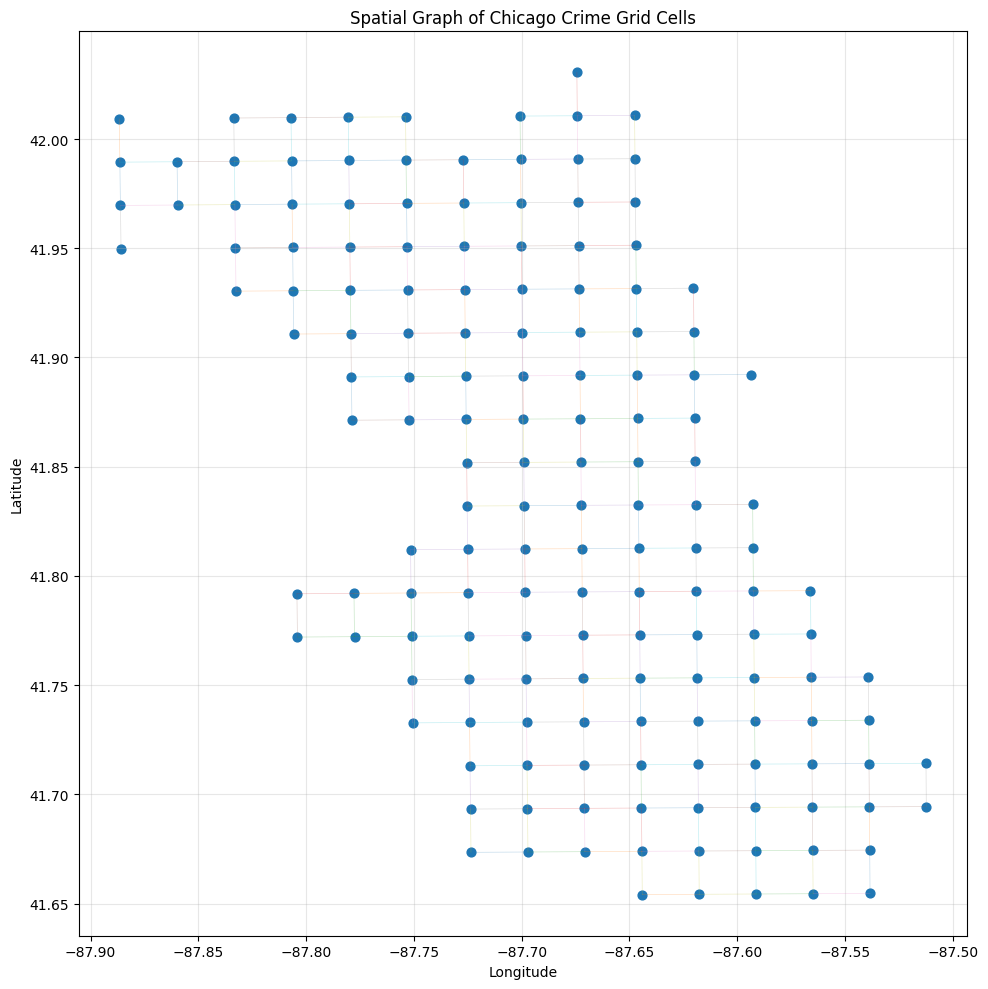

In [15]:
plt.figure(figsize=(10, 10))

# Draw edges
for source, target in undirected_edges:

    x_values = [
        grid_nodes.loc[source, "GRID_CENTER_LON"],
        grid_nodes.loc[target, "GRID_CENTER_LON"]
    ]

    y_values = [
        grid_nodes.loc[source, "GRID_CENTER_LAT"],
        grid_nodes.loc[target, "GRID_CENTER_LAT"]
    ]

    plt.plot(
        x_values,
        y_values,
        linewidth=0.5,
        alpha=0.25
    )

# Draw nodes
plt.scatter(
    grid_nodes["GRID_CENTER_LON"],
    grid_nodes["GRID_CENTER_LAT"],
    s=40
)

plt.title("Spatial Graph of Chicago Crime Grid Cells")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5.2 — Calculate Haversine Distance and Edge Weights

### Create the Haversine function

In [16]:
import math

def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the great-circle distance between
    two latitude/longitude points.

    Returns distance in kilometers.
    """

    R = 6371.0  # Earth radius in kilometers

    lat1 = math.radians(lat1)
    lon1 = math.radians(lon1)
    lat2 = math.radians(lat2)
    lon2 = math.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        math.sin(dlat / 2) ** 2
        + math.cos(lat1)
        * math.cos(lat2)
        * math.sin(dlon / 2) ** 2
    )

    c = 2 * math.asin(math.sqrt(a))

    return R * c

### Test the function

In [17]:
# Test using the first two grid nodes

node_0 = grid_nodes.iloc[0]
node_1 = grid_nodes.iloc[1]

distance = haversine_distance(
    node_0["GRID_CENTER_LAT"],
    node_0["GRID_CENTER_LON"],
    node_1["GRID_CENTER_LAT"],
    node_1["GRID_CENTER_LON"]
)

print(f"Distance between Node 0 and Node 1: {distance:.4f} km")

Distance between Node 0 and Node 1: 2.1951 km


### Calculate distance for every edge

In [18]:
edge_data = []

for source, target in undirected_edges:

    source_node = grid_nodes.loc[source]
    target_node = grid_nodes.loc[target]

    distance_km = haversine_distance(
        source_node["GRID_CENTER_LAT"],
        source_node["GRID_CENTER_LON"],
        target_node["GRID_CENTER_LAT"],
        target_node["GRID_CENTER_LON"]
    )

    edge_data.append({
        "SOURCE": source,
        "TARGET": target,
        "DISTANCE_KM": distance_km
    })

edges_df = pd.DataFrame(edge_data)

print("Edge distance calculation completed.")
print("Number of edges:", len(edges_df))

display(edges_df.head(10))

Edge distance calculation completed.
Number of edges: 272


,SOURCE,TARGET,DISTANCE_KM
0,72,73,2.195064
1,67,68,2.195085
2,44,45,2.195078
3,90,97,2.203244
4,99,100,2.195060
5,20,29,2.203350
6,8,9,2.195088
7,40,41,2.195051
8,46,57,2.203316
9,9,17,2.203340


### Check distance statistics

In [20]:
print("Haversine distance statistics:")
print(
    edges_df["DISTANCE_KM"].describe()
)

print(
    f"Minimum edge distance: "
    f"{edges_df['DISTANCE_KM'].min():.4f} km"
)

print(
    f"Maximum edge distance: "
    f"{edges_df['DISTANCE_KM'].max():.4f} km"
)

print(
    f"Average edge distance: "
    f"{edges_df['DISTANCE_KM'].mean():.4f} km"
)

print(
    f"Median edge distance: "
    f"{edges_df['DISTANCE_KM'].median():.4f} km"
)

Haversine distance statistics:
count    272.000000
mean       2.199219
std        0.004113
min        2.194981
25%        2.195056
50%        2.203155
75%        2.203267
max        2.203365
Name: DISTANCE_KM, dtype: float64
Minimum edge distance: 2.1950 km
Maximum edge distance: 2.2034 km
Average edge distance: 2.1992 km
Median edge distance: 2.2032 km


### Verify the 3 km threshold

In [21]:
print(
    "Edges within 3 km:",
    (edges_df["DISTANCE_KM"] <= 3.0).sum()
)

print(
    "Edges above 3 km:",
    (edges_df["DISTANCE_KM"] > 3.0).sum()
)

print(
    "Maximum distance:",
    edges_df["DISTANCE_KM"].max()
)

Edges within 3 km: 272
Edges above 3 km: 0
Maximum distance: 2.2033649569666074


### Calculate inverse-distance edge weight

In [22]:
edges_df["EDGE_WEIGHT"] = (
    1 / edges_df["DISTANCE_KM"]
)

display(edges_df.head(10))

,SOURCE,TARGET,DISTANCE_KM,EDGE_WEIGHT
0,72,73,2.195064,0.455568
1,67,68,2.195085,0.455563
2,44,45,2.195078,0.455565
3,90,97,2.203244,0.453876
4,99,100,2.195060,0.455568
5,20,29,2.203350,0.453854
6,8,9,2.195088,0.455563
7,40,41,2.195051,0.455570
8,46,57,2.203316,0.453861
9,9,17,2.203340,0.453856


### Weight statistics

In [23]:
print("Edge weight statistics:")
print(
    edges_df["EDGE_WEIGHT"].describe()
)

print(
    f"Minimum edge weight: "
    f"{edges_df['EDGE_WEIGHT'].min():.6f}"
)

print(
    f"Maximum edge weight: "
    f"{edges_df['EDGE_WEIGHT'].max():.6f}"
)

print(
    f"Average edge weight: "
    f"{edges_df['EDGE_WEIGHT'].mean():.6f}"
)

Edge weight statistics:
count    272.000000
mean       0.454708
std        0.000850
min        0.453851
25%        0.453871
50%        0.453894
75%        0.455569
max        0.455585
Name: EDGE_WEIGHT, dtype: float64
Minimum edge weight: 0.453851
Maximum edge weight: 0.455585
Average edge weight: 0.454708


### Plot edge-distance distribution

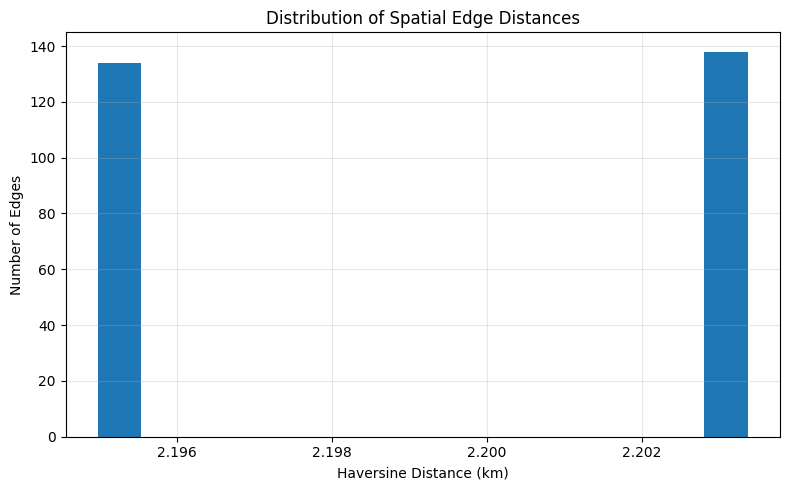

In [24]:
plt.figure(figsize=(8, 5))

plt.hist(
    edges_df["DISTANCE_KM"],
    bins=15
)

plt.title("Distribution of Spatial Edge Distances")
plt.xlabel("Haversine Distance (km)")
plt.ylabel("Number of Edges")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Plot edge-weight distribution

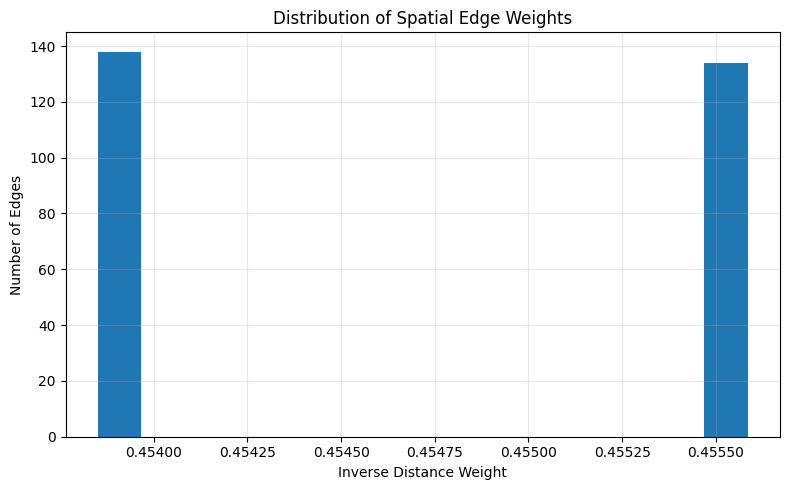

In [25]:
plt.figure(figsize=(8, 5))

plt.hist(
    edges_df["EDGE_WEIGHT"],
    bins=15
)

plt.title("Distribution of Spatial Edge Weights")
plt.xlabel("Inverse Distance Weight")
plt.ylabel("Number of Edges")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Inspect strongest connections

In [26]:
strongest_edges = edges_df.sort_values(
    "EDGE_WEIGHT",
    ascending=False
).head(10)

display(strongest_edges)

,SOURCE,TARGET,DISTANCE_KM,EDGE_WEIGHT
89,138,139,2.194981,0.455585
216,128,129,2.194984,0.455584
245,139,140,2.194990,0.455583
28,129,130,2.194992,0.455582
115,149,150,2.194995,0.455582
48,140,141,2.194998,0.455581
260,130,131,2.195000,0.455581
165,120,121,2.195003,0.455580
205,150,151,2.195003,0.455580
71,110,111,2.195005,0.455580


### Inspect weakest connections

In [27]:
weakest_edges = edges_df.sort_values(
    "EDGE_WEIGHT",
    ascending=True
).head(10)

display(weakest_edges)

,SOURCE,TARGET,DISTANCE_KM,EDGE_WEIGHT
200,4,12,2.203365,0.453851
168,3,11,2.203359,0.453852
41,12,20,2.203357,0.453853
227,21,30,2.203355,0.453853
159,2,10,2.203354,0.453854
235,11,19,2.203352,0.453854
5,20,29,2.203350,0.453854
138,1,9,2.203348,0.453855
209,10,18,2.203346,0.453855
185,19,28,2.203344,0.453856


# 5.3 — Build the Weighted Adjacency Matrix

### Create the adjacency matrix

In [28]:
# Number of spatial nodes
num_nodes = len(grid_nodes)

# Initialize adjacency matrix with zeros
adjacency_matrix = np.zeros(
    (num_nodes, num_nodes),
    dtype=float
)

# Fill the matrix using the edge weights
for _, row in edges_df.iterrows():

    source = int(row["SOURCE"])
    target = int(row["TARGET"])
    weight = row["EDGE_WEIGHT"]

    # Undirected graph
    adjacency_matrix[source, target] = weight
    adjacency_matrix[target, source] = weight

print("Weighted adjacency matrix created.")

print("Shape:", adjacency_matrix.shape)

Weighted adjacency matrix created.
Shape: (157, 157)


### Check the matrix

In [29]:
print("Minimum value:", adjacency_matrix.min())
print("Maximum value:", adjacency_matrix.max())

print(
    "Number of non-zero connections:",
    np.count_nonzero(adjacency_matrix)
)

print(
    "Expected non-zero connections:",
    len(edges_df) * 2
)

Minimum value: 0.0
Maximum value: 0.4555847421826671
Number of non-zero connections: 544
Expected non-zero connections: 544


## Verify symmetry

#### Because our graph is undirected: A[i,j] = A[j,i]

In [30]:
is_symmetric = np.allclose(
    adjacency_matrix,
    adjacency_matrix.T
)

print("Is adjacency matrix symmetric?", is_symmetric)

Is adjacency matrix symmetric? True


### Check diagonal

In [31]:
diagonal_values = np.diag(adjacency_matrix)

print(
    "Number of self-connections:",
    np.count_nonzero(diagonal_values)
)

print(
    "Maximum diagonal value:",
    diagonal_values.max()
)

Number of self-connections: 0
Maximum diagonal value: 0.0


### Display a small part of the matrix

In [33]:
pd.DataFrame(
    adjacency_matrix[:10, :10],
    index=[f"Node {i}" for i in range(10)],
    columns=[f"Node {i}" for i in range(10)]
)

,Node 0,Node 1,Node 2,Node 3,Node 4,Node 5,Node 6,Node 7,Node 8,Node 9
Node 0,0.000000,0.455562,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.453856,0.000000
Node 1,0.455562,0.000000,0.455561,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.453855
Node 2,0.000000,0.455561,0.000000,0.455560,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Node 3,0.000000,0.000000,0.455560,0.000000,0.455558,0.000000,0.000000,0.000000,0.000000,0.000000
Node 4,0.000000,0.000000,0.000000,0.455558,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Node 5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.455567,0.000000,0.000000,0.000000
Node 6,0.000000,0.000000,0.000000,0.000000,0.000000,0.455567,0.000000,0.455565,0.000000,0.000000
Node 7,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.455565,0.000000,0.455564,0.000000
Node 8,0.453856,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.455564,0.000000,0.455563
Node 9,0.000000,0.453855,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.455563,0.000000


### Visualize the adjacency matrix

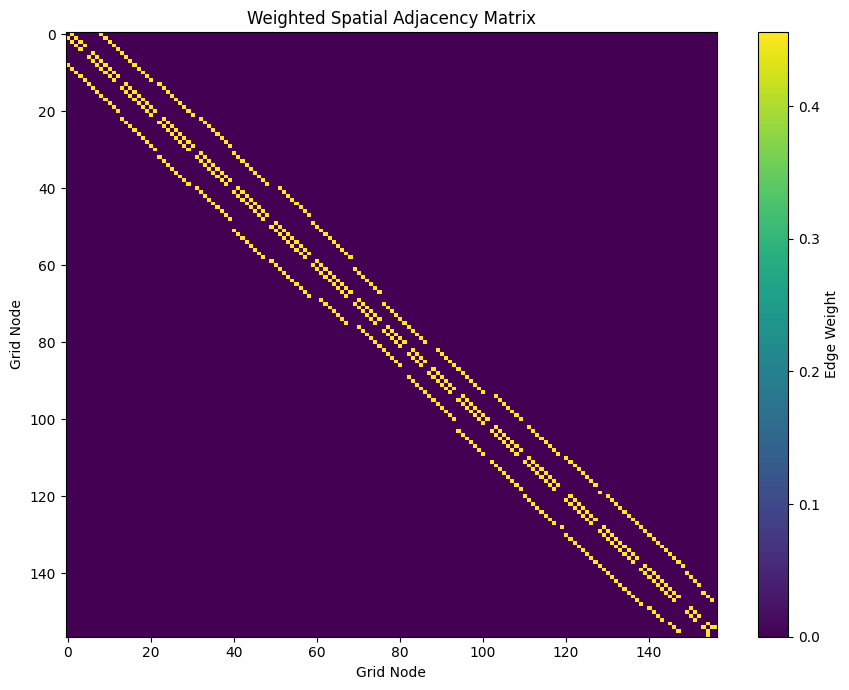

In [34]:
plt.figure(figsize=(9, 7))

plt.imshow(
    adjacency_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Edge Weight"
)

plt.title("Weighted Spatial Adjacency Matrix")
plt.xlabel("Grid Node")
plt.ylabel("Grid Node")

plt.tight_layout()
plt.show()

## Calculate node degree and weighted degree

#### We already calculated the number of neighbors. Now we calculate the weighted degree. This is the sum of all connection weights for each node.

In [35]:
weighted_degree = adjacency_matrix.sum(axis=1)

grid_nodes["WEIGHTED_DEGREE"] = weighted_degree

print("Weighted degree statistics:")
print(
    grid_nodes["WEIGHTED_DEGREE"].describe()
)

Weighted degree statistics:
count    157.000000
mean       1.575550
std        0.369641
min        0.453886
25%        1.363338
50%        1.818853
75%        1.818889
max        1.818949
Name: WEIGHTED_DEGREE, dtype: float64


## Find strongest spatially connected nodes

In [36]:
strongest_nodes = grid_nodes.sort_values(
    "WEIGHTED_DEGREE",
    ascending=False
).head(10)

display(
    strongest_nodes[
        [
            "NODE_ID",
            "GRID_ID",
            "CRIME_COUNT",
            "DEGREE",
            "WEIGHTED_DEGREE"
        ]
    ]
)

,NODE_ID,GRID_ID,CRIME_COUNT,DEGREE,WEIGHTED_DEGREE
140,140,17_2,154,4,1.818949
130,130,16_2,247,4,1.818945
141,141,17_3,357,4,1.818943
131,131,16_3,244,4,1.818939
142,142,17_4,466,4,1.818936
121,121,15_3,480,4,1.818934
132,132,16_4,680,4,1.818932
111,111,14_3,769,4,1.818930
143,143,17_5,186,4,1.818930
122,122,15_4,1138,4,1.818928


## Compare crime count and spatial connectivity

In [37]:
correlation = grid_nodes[
    ["CRIME_COUNT", "WEIGHTED_DEGREE"]
].corr()

display(correlation)

,CRIME_COUNT,WEIGHTED_DEGREE
CRIME_COUNT,1.000000,0.450594
WEIGHTED_DEGREE,0.450594,1.000000


# Save the adjacency matrix

In [38]:
adjacency_file = "data/spatial_adjacency_matrix.npy"

np.save(
    adjacency_file,
    adjacency_matrix
)

print("Adjacency matrix saved to:")
print(adjacency_file)

Adjacency matrix saved to:
data/spatial_adjacency_matrix.npy


## Save the edge table

In [39]:
edge_file = "data/spatial_edges.csv"

edges_df.to_csv(
    edge_file,
    index=False
)

print("Edge table saved to:")
print(edge_file)

Edge table saved to:
data/spatial_edges.csv


### Final verification

In [40]:
loaded_adjacency = np.load(
    adjacency_file
)

loaded_edges = pd.read_csv(
    edge_file
)

print("Verification completed.")

print(
    "Adjacency matrix shape:",
    loaded_adjacency.shape
)

print(
    "Number of edges:",
    len(loaded_edges)
)

print(
    "Matrix symmetric:",
    np.allclose(
        loaded_adjacency,
        loaded_adjacency.T
    )
)

Verification completed.
Adjacency matrix shape: (157, 157)
Number of edges: 272
Matrix symmetric: True
